# Prompt 09: extensions (sections 1-5, with pass 2 fixes)

**Status:** pass 1 and pass 2 run 2026-11-07. Drivers: `code/R/09a_fang_crosscheck.R`, `09b_by_type.R`, `09c_ai_impact.R`, `09d_national_drivers.R`, `09e_pass2_checks.R`, `09f_index_addon.R`, `09g_land_sensitivity.R`; tables from `code/python/09_extend_tables.py`. Results: `results/2026-11-07/extend/`. Every model was pre-registered in `EXPERIMENTS.md` section 14 before it ran. Deviations X1-X5 and F27 are logged there; X5 and F27 were added after seeing results and are labeled.

**Main spec unless stated:** 50 states, two-way FE, AI(t-1), ctrl4, clustered by state, winsorized 1/99. Two AI measures: private data-center jobs per 1,000 workers (2015-2025) and AI postings per 1,000 workers (lag 2019-2025); in section 5, also the AI index. **A finding** needs BH q < 0.10 within its family and a lead (AI(t+1)) that is clearly smaller (|lead| < 0.5 x |lag| and lead p >= 0.10). All results are associations.

**What pass 2 changed:** SEDS as published in June 2023 is the main old-basis series; state-specific trend checks; bounds per within-state SD; the relevance test and per-state slope ranks; the full drivers model (LBNL wind cost, CRS-coded tax credits); the section 5 index; and the add-on (groupings, land moderator, every result also without CA, CO and DE). **Not run:** the Queued Up outcome (the file wasn't obtainable by script), the innovation dimension (no inventor locations), and the Table A1 and Supplement B comparisons (the file received was the article, not the supplement).

In [1]:
import pandas as pd
from IPython.display import display, Image, Markdown
pd.set_option('display.width', 220); pd.set_option('display.max_columns', 30); pd.set_option('display.max_colwidth', 60); pd.set_option('display.max_rows', 160)
T = '../results/2026-11-07/extend/tables/'; F = '../results/2026-11-07/extend/figures/'

## 1. Does our data match Fang's? (no year FE)

**Question:** do our variables and Fang's Table 2 line up, and what do trend tests say about Fang's spec?

**What we ran:** Fang's Table A1 isn't available (the supplement wasn't received), so we compare against the means implied by Table 2's constants (Stata-style FE constants, with mean ln AI fixed at ours). Table 2 on current SEDS, k = 2.6, the year-by-year rebuild, and **SEDS as published in June 2023 (the main old-basis series from pass 2)**. A decomposition of the gap between current and June 2023 SEDS. Fang's column 6 with a linear trend, and with ln employment in two non-energy industries in place of AI (distilleries, pet care; chosen before any regression), on current and June 2023 SEDS. The bridge's final spec on each basis (the June 2023 release ends in 2021, so its samples are 2015-2021 for jobs and 2019-2021 for postings).

$$\ln ET_{it} = \beta_1 \ln X_{it} + \beta_2 \ln EPU_{it} + \textstyle\sum_k \beta_k \ln CV_{kit} + [\delta\, t] + \alpha_i + \varepsilon_{it},\quad X \in \{AI,\ \text{distillery jobs},\ \text{pet-care jobs}\}$$

,variable,basis,N,mean,sd,fang_implied_mean,diff,diff_sd,flag,unit_shift_match
0,lnET,current SEDS,204,11.437,1.103,11.786,-0.349,-0.316,True,NaN
1,lnET_k26,k = 2.6,204,11.846,1.125,11.786,0.060,0.053,False,NaN
2,lnET_rb,rebuilt,204,11.827,1.129,11.786,0.041,0.036,False,NaN
3,lnAIp,NaN,204,7.701,1.479,7.701,0.000,0.000,False,NaN
4,lnEPU,NaN,204,5.382,0.597,5.295,0.087,0.146,False,NaN
5,lnEP,NaN,204,2.927,0.193,2.924,0.004,0.019,False,NaN
6,lnGDP,NaN,204,12.350,1.050,12.258,0.092,0.088,False,consistent with chained 2012 vs 2017 dollars (expected 0...
7,lnPOP,NaN,204,8.272,1.036,8.278,-0.006,-0.006,False,NaN
8,lnEDU,NaN,204,4.232,0.312,4.231,0.001,0.002,False,NaN


,ai_measure,column,fang_published,current,k_2.6,rebuilt,archived_jun2023,archived_jun2023_ci95
0,ln AI postings,1,0.0428,-0.0288**,+0.0251*,+0.0149,+0.0346***,"[+0.0086, +0.0605]"
1,ln AI postings,2,0.0452,-0.0100,+0.0342**,+0.0269*,+0.0435***,"[+0.0166, +0.0704]"
2,ln AI postings,3,0.0396,-0.0189,+0.0219,+0.0120,+0.0316**,"[+0.0010, +0.0621]"
3,ln AI postings,4,0.0548,-0.0159,+0.0237,+0.0155,+0.0361**,"[+0.0010, +0.0713]"
4,ln AI postings,5,0.0561,-0.0183,+0.0213,+0.0133,+0.0338*,"[-0.0020, +0.0696]"
5,ln AI postings,6,0.0531,-0.0188,+0.0216,+0.0137,+0.0348*,"[-0.0011, +0.0706]"
21,ln data-center jobs,1,0.0428,-0.0950*,+0.0144,+0.0022,+0.0224,"[-0.0729, +0.1178]"
22,ln data-center jobs,2,0.0452,-0.0503,+0.0299,+0.0259,+0.0355,"[-0.0615, +0.1326]"
23,ln data-center jobs,3,0.0396,-0.0735,-0.0216,-0.0272,-0.0209,"[-0.1235, +0.0818]"
24,ln data-center jobs,4,0.0548,-0.0674,-0.0272,-0.0285,-0.0269,"[-0.1315, +0.0777]"


,ai_measure,column,current,rebuilt,june2023,gap_june2023_minus_current,share_accounting_rebuild,share_later_data_revisions,fang,june2023_as_share_of_fang
0,ln AI postings,1,-0.0288,0.0149,0.0346,0.0634,0.690,0.310,0.0428,0.808
1,ln AI postings,2,-0.0100,0.0269,0.0435,0.0535,0.691,0.309,0.0452,0.962
2,ln AI postings,6,-0.0188,0.0137,0.0348,0.0536,0.606,0.394,0.0531,0.655
3,ln data-center jobs,1,-0.0950,0.0022,0.0224,0.1174,0.828,0.172,0.0428,0.524
4,ln data-center jobs,2,-0.0503,0.0259,0.0355,0.0859,0.888,0.112,0.0452,0.786
5,ln data-center jobs,6,-0.0655,-0.0242,-0.0207,0.0448,0.922,0.078,0.0531,-0.389


,block,spec,ai_measure,outcome,term,estimate,se,pval,N
0,p1trend,fang6,aipostings,lnET_arch,AI,0.0348,0.0182,0.0575,204
1,p1trend,fang6trend,aipostings,lnET_arch,AI,-0.0419,0.0268,0.1209,204
2,p1trend,fang6trend,aipostings,lnET_arch,trend,0.0482,0.0128,0.0003,204
3,p1trend,fang6,dcjobs,lnET_arch,AI,-0.0207,0.0533,0.6988,204
4,p1trend,fang6trend,dcjobs,lnET_arch,AI,-0.0674,0.0518,0.1955,204
5,p1trend,fang6trend,dcjobs,lnET_arch,trend,0.0353,0.0086,0.0001,204
6,p1placebo,fang6,distilleries,lnET_arch,AI,0.1003,0.0481,0.0397,135
7,p1placebo,fang6trend,distilleries,lnET_arch,AI,0.0757,0.0542,0.1656,135
8,p1placebo,fang6,petcare,lnET_arch,AI,0.2980,0.1001,0.0034,202
9,p1placebo,fang6trend,petcare,lnET_arch,AI,0.1339,0.1160,0.2504,202


,block,spec,ai_measure,outcome,term,estimate,pval,N
0,trend,fang6,aipostings,lnET,AI,-0.0188,0.3172,204
1,trend,fang6trend,aipostings,lnET,AI,-0.0392,0.1765,204
2,trend,fang6trend,aipostings,lnET,trend,0.0129,0.3540,204
3,trend,fang6,dcjobs,lnET,AI,-0.0655,0.2290,204
4,trend,fang6trend,dcjobs,lnET,AI,-0.0668,0.2329,204
5,trend,fang6trend,dcjobs,lnET,trend,0.0010,0.9166,204
6,trend,fang6,aipostings,lnET_rb,AI,0.0137,0.4999,204
7,trend,fang6trend,aipostings,lnET_rb,AI,-0.0555,0.0698,204
8,trend,fang6trend,aipostings,lnET_rb,trend,0.0435,0.0033,204
9,trend,fang6,dcjobs,lnET_rb,AI,-0.0242,0.6813,204


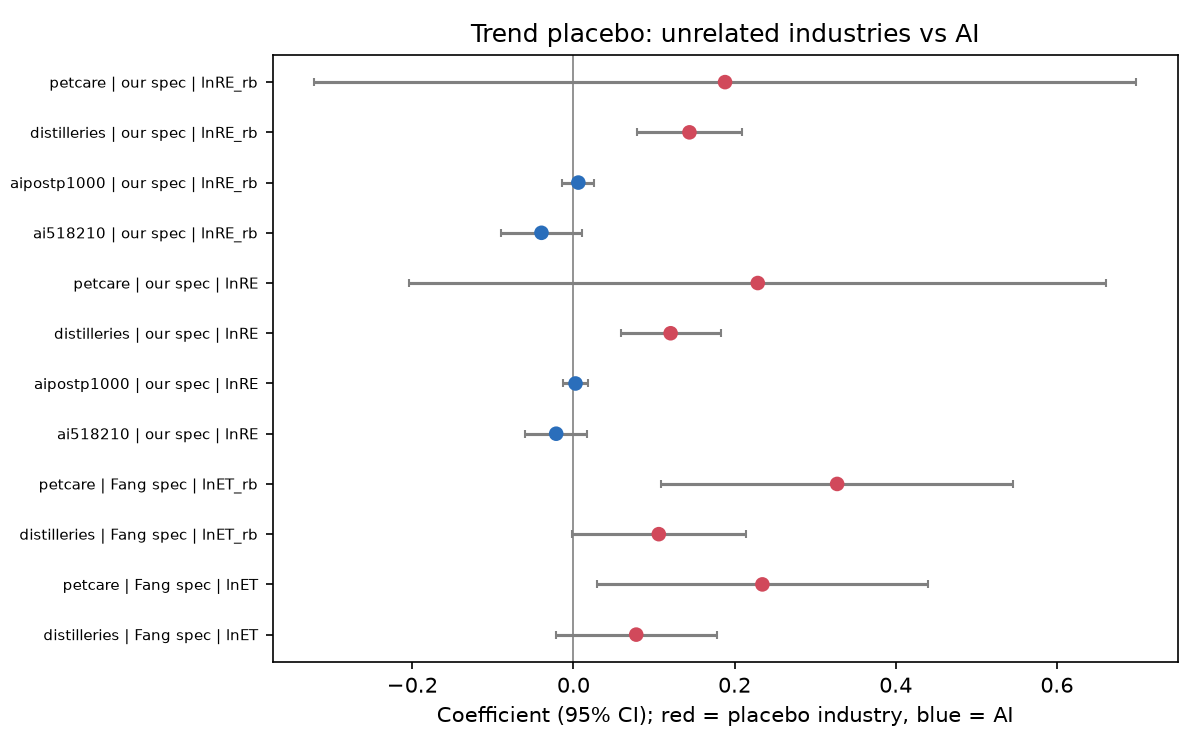

**Verdict.** Our data match Fang's on every regressor: the means implied by Fang's Table 2 constants are within 0.15 SD of ours (GDP's gap fits 2012 vs 2017 dollars). The outcome is what differs. On current SEDS, our mean ln renewables is -0.32 SD below Fang's implied mean, the only flagged row; on the old fossil-fuel-equivalence basis the gap is about 0.04-0.06 SD. **SEDS as published in June 2023 largely reproduces Fang:** the same sign, a similar size in columns 1-2 (+0.0346 and +0.0435 against +0.0428 and +0.0452), and about two-thirds of Fang's size in column 6 (+0.0348, p = 0.057, against +0.0531). Of the move from current to June 2023 SEDS, 61% (column 6, postings) comes from the accounting change and the rest from EIA's later data revisions. But Fang's spec has no year effects, and on the June 2023 basis a linear trend turns column 6 to -0.0419 (p = 0.121), while pet-care employment, which has nothing to do with energy, is associated with renewables more strongly than AI (+0.2980, p = 0.003; distilleries +0.1003, p = 0.040). In our final spec, the June 2023 basis gives -0.0211 (p = 0.635; 2019-2021, the years the release covers) for postings. Year effects remove national trends but not state-specific ones: distillery employment stays significant in our spec even with state linear trends (+0.0675, p = 0.040).


In [2]:
ds = pd.read_csv(T + 's1_descriptives_comparison.csv')
display(ds[['variable', 'basis', 'N', 'mean', 'sd', 'fang_implied_mean', 'diff', 'diff_sd', 'flag', 'unit_shift_match']].round(3))
t2 = pd.read_csv(T + 's1_table2_four_versions.csv')
display(t2[t2.term == 'AI'][['ai_measure', 'column', 'fang_published', 'current', 'k_2.6', 'rebuilt', 'archived_jun2023', 'archived_jun2023_ci95']])
display(pd.read_csv(T + 'p2_gap_decomposition.csv').drop(columns='tags'))
display(pd.read_csv(T + 's1_june2023_trend_placebo_final.csv')[['block', 'spec', 'ai_measure', 'outcome', 'term', 'estimate', 'se', 'pval', 'N']].round(4))
display(pd.read_csv(T + 's1_trend_placebo.csv')[['block', 'spec', 'ai_measure', 'outcome', 'term', 'estimate', 'pval', 'N']].round(4))
display(Image(F + 'fig_s1_trend_placebo.png', width=720))
display(Markdown(open(T + 's1_verdict.md').read()))

### State-specific trends and the distillery placebo (pass 2)
Distillery employment was significant in our spec, so year effects don't remove state-specific trends. Below: the main spec with state linear trends added, for the final bridge spec and the placebos, and the distillery placebo rerun on the 13 states with no suppressed year in 2014-2024 (38 states have at least one).

In [3]:
st = pd.read_csv(T + 'p2_state_trends_side_by_side.csv')
display(st[st.block.isin(['p2bridge', 'p2placebo', 'p2h1'])].round(4))
display(pd.read_csv(T + 'p2_distillery_suppression.csv'))
display(pd.read_csv(T + 'p2_distillery_rerun.csv').drop(columns='tag').round(4))

,block,ai_measure,outcome,N_twfe,N_twfe_trend,estimate_twfe,estimate_twfe_trend,pval_twfe,pval_twfe_trend,se_twfe,se_twfe_trend
0,p2bridge,aipostings,lnET,300.0,300.0,-0.0479,-0.0265,0.1089,0.2432,0.0293,0.0224
1,p2bridge,aipostings,lnET_arch,150.0,150.0,-0.0211,0.0098,0.6353,0.8762,0.0443,0.0623
2,p2bridge,aipostings,lnET_rb,300.0,300.0,-0.0478,-0.0440,0.1273,0.1310,0.0308,0.0286
3,p2bridge,dcjobs,lnET,500.0,500.0,-0.0567,-0.0074,0.2076,0.8024,0.0444,0.0293
4,p2bridge,dcjobs,lnET_arch,350.0,350.0,-0.0689,0.0062,0.1974,0.8736,0.0527,0.0388
5,p2bridge,dcjobs,lnET_rb,500.0,500.0,-0.0969,-0.0031,0.0952,0.9367,0.0570,0.0385
44,p2h1,ai518210,ln_ec,550.0,550.0,-0.0016,0.0022,0.7946,0.4906,0.0060,0.0032
45,p2h1,ai518210,ln_ee,550.0,550.0,0.0022,-0.0002,0.7073,0.9398,0.0058,0.0024
46,p2h1,ai518210,renew_share,550.0,550.0,-0.0101,0.0060,0.1002,0.1960,0.0060,0.0045
47,p2h1,aipostp1000,ln_ec,350.0,350.0,-0.0017,-0.0028,0.5997,0.0961,0.0033,0.0017


,state,years_suppressed,years
0,CT,11,2014;2015;2016;2017;2018;2019;2020;2021;2022;2023;2024
1,ND,11,2014;2015;2016;2017;2018;2019;2020;2021;2022;2023;2024
2,NM,11,2014;2015;2016;2017;2018;2019;2020;2021;2022;2023;2024
3,OK,11,2014;2015;2016;2017;2018;2019;2020;2021;2022;2023;2024
4,SD,11,2014;2015;2016;2017;2018;2019;2020;2021;2022;2023;2024
5,AL,10,2014;2015;2016;2017;2018;2020;2021;2022;2023;2024
6,DE,10,2014;2015;2016;2017;2018;2019;2020;2022;2023;2024
7,MO,10,2014;2015;2016;2017;2018;2019;2020;2021;2023;2024
8,OR,9,2014;2015;2016;2017;2018;2019;2020;2021;2022
9,RI,9,2014;2015;2016;2017;2018;2019;2020;2022;2024


,spec,trend,outcome,states,estimate,pval,N,n_states
0,Fang col. 6,False,lnET,all_nonsuppressed_obs,0.0779,0.1241,135,51
1,Fang col. 6,True,lnET,all_nonsuppressed_obs,0.1210,0.0333,135,51
2,Fang col. 6,False,lnET_arch,all_nonsuppressed_obs,0.1003,0.0397,135,51
3,Fang col. 6,True,lnET_arch,all_nonsuppressed_obs,0.0757,0.1656,135,51
4,Fang col. 6,False,lnET,never_suppressed_states,0.0346,0.5937,52,13
5,Fang col. 6,True,lnET,never_suppressed_states,0.0846,0.2264,52,13
6,Fang col. 6,False,lnET_arch,never_suppressed_states,0.0441,0.4732,52,13
7,Fang col. 6,True,lnET_arch,never_suppressed_states,0.0785,0.2449,52,13
8,our main spec,False,lnRE,all_nonsuppressed_obs,0.1062,0.0009,298,50
9,our main spec,True,lnRE,all_nonsuppressed_obs,0.0610,0.0447,298,50


**Reading:** our regressors match Fang's, and SEDS as published in June 2023 largely reproduces Fang (same sign, similar size in columns 1-2, about two-thirds of Fang's size in column 6, p = 0.057). About 60-70% of the move from current SEDS comes from the accounting change and the rest from later data revisions.
But Fang's positive doesn't survive a linear trend, unrelated industries "explain" renewables as well or better, and the distillery placebo stays significant in our spec even with state trends on never-suppressed states (p = 0.014). State-specific trends are a live problem for any state-level AI association.

## 2. Which renewable did AI move? And Georgia

**Question:** is the association concentrated in one renewable type, and is the negative SEDS total transport fuel?

**What we ran:** main spec on 19 by-type outcomes x 2 AI measures (family "bytype"; ln geothermal generation isn't estimable: 7 states). BH q-values; lead placebo for p < 0.10; pass 2 adds state linear trends to every row.

$$Y_{st} = \beta\, AI_{s,t-1} + \gamma'\text{ctrl4}_{st} + \mu_s + \tau_t\ [+\ \mu_s t] + \varepsilon_{st}$$

,outcome_label,ai,coef,ci95,pval,qval,N,years,lead_placebo,finding,status
0,wind: share of generation,"jobs per 1,000",-0.008413,"[-0.0218, +0.00499]",0.212966,0.662252,550.0,2015-2025,NaN,False,ok
1,wind: share of generation,"postings per 1,000",-0.0007843,"[-0.0051, +0.00353]",0.716230,0.776879,350.0,2019-2025,NaN,False,ok
2,wind: ln generation,"jobs per 1,000",-0.1805**,"[-0.326, -0.0349]",0.016368,0.147316,455.0,2015-2025,lead -0.276 (p=0.016) vs lag -0.191,False,ok
3,wind: ln generation,"postings per 1,000",-0.0477***,"[-0.0775, -0.0179]",0.002390,0.086049,293.0,2019-2025,lead -0.00797 (p=0.681) vs lag -0.0419,True,ok
4,"wind: MW added per 1,000 MW (2015 cap.)","jobs per 1,000",+1.887**,"[+0.39, +3.38]",0.014538,0.147316,550.0,2015-2025,lead +0.799 (p=0.476) vs lag +1.57,False,ok
5,"wind: MW added per 1,000 MW (2015 cap.)","postings per 1,000",+0.5947,"[-1.11, +2.3]",0.485921,0.662252,350.0,2019-2025,NaN,False,ok
6,utility solar: share of generation,"jobs per 1,000",-5.93e-05,"[-0.00606, +0.00594]",0.984238,0.984238,550.0,2015-2025,NaN,False,ok
7,utility solar: share of generation,"postings per 1,000",-0.000975,"[-0.00371, +0.00176]",0.477094,0.662252,350.0,2019-2025,NaN,False,ok
8,utility solar: ln generation,"jobs per 1,000",+0.04204,"[-0.218, +0.302]",0.746152,0.776879,499.0,2015-2025,NaN,False,ok
9,utility solar: ln generation,"postings per 1,000",-0.04603,"[-0.206, +0.114]",0.564995,0.701373,333.0,2019-2025,NaN,False,ok


,block,ai_measure,outcome,N_twfe,N_twfe_trend,estimate_twfe,estimate_twfe_trend,pval_twfe,pval_twfe_trend,se_twfe,se_twfe_trend
6,p2bytype,ai518210,add_bio_per1000,550.0,550.0,-0.1359,0.0311,0.3115,0.9013,0.1329,0.2491
7,p2bytype,ai518210,add_geo_per1000,550.0,550.0,0.0023,0.0035,0.7311,0.7757,0.0066,0.0122
8,p2bytype,ai518210,add_hydro_per1000,550.0,550.0,0.0746,0.3147,0.4967,0.2549,0.1090,0.2731
9,p2bytype,ai518210,add_solar_per1000,550.0,550.0,-0.5994,-3.5372,0.7553,0.0698,1.9126,1.9084
10,p2bytype,ai518210,add_wind_per1000,550.0,550.0,1.8869,1.0455,0.0145,0.4998,0.7447,1.5378
11,p2bytype,ai518210,ln_gen_bio,526.0,526.0,-0.0197,0.0421,0.3912,0.2645,0.0228,0.0373
12,p2bytype,ai518210,ln_gen_hydro,528.0,528.0,-0.0339,0.0279,0.0702,0.5369,0.0183,0.0448
13,p2bytype,ai518210,ln_gen_solar,499.0,499.0,0.0420,-0.1181,0.7462,0.3308,0.1291,0.1202
14,p2bytype,ai518210,ln_gen_wind,455.0,455.0,-0.1805,-0.1385,0.0164,0.2383,0.0722,0.1158
15,p2bytype,ai518210,ln_seds_biofuels,494.0,494.0,0.0074,-0.0113,0.5524,0.2889,0.0124,0.0106


**Biomass and what drives the negative SEDS total (pass 2, item 4):**

,outcome,ai_measure,estimate,ci_lo,ci_hi,pval,qval,N,outcome_label
0,share_bio,ai518210,0.0005,-0.0012,0.0021,0.5866,0.7040,550.0,biomass: share of generation
1,share_bio,aipostp1000,-0.0004,-0.0014,0.0005,0.3428,0.6623,350.0,biomass: share of generation
2,ln_gen_bio,ai518210,-0.0197,-0.0655,0.0261,0.3912,0.6623,526.0,biomass: ln generation
3,ln_gen_bio,aipostp1000,0.0347,0.0045,0.0649,0.0252,0.1815,337.0,biomass: ln generation
4,ln_seds_woodwaste,ai518210,-0.0217,-0.0678,0.0243,0.3473,0.6623,500.0,SEDS wood and waste (ln)
5,ln_seds_woodwaste,aipostp1000,0.0102,-0.0154,0.0358,0.4265,0.6623,300.0,SEDS wood and waste (ln)
6,ln_seds_biofuels,ai518210,0.0074,-0.0175,0.0323,0.5524,0.7014,494.0,SEDS biofuels (ln)
7,ln_seds_biofuels,aipostp1000,-0.0092,-0.0290,0.0107,0.3573,0.6623,294.0,SEDS biofuels (ln)
8,ln_seds_re_exbiomass,ai518210,-0.0552,-0.1373,0.0268,0.1825,0.6623,500.0,SEDS renewables excl. all biomass (ln)
9,ln_seds_re_exbiomass,aipostp1000,0.0203,-0.0188,0.0594,0.3023,0.6623,300.0,SEDS renewables excl. all biomass (ln)


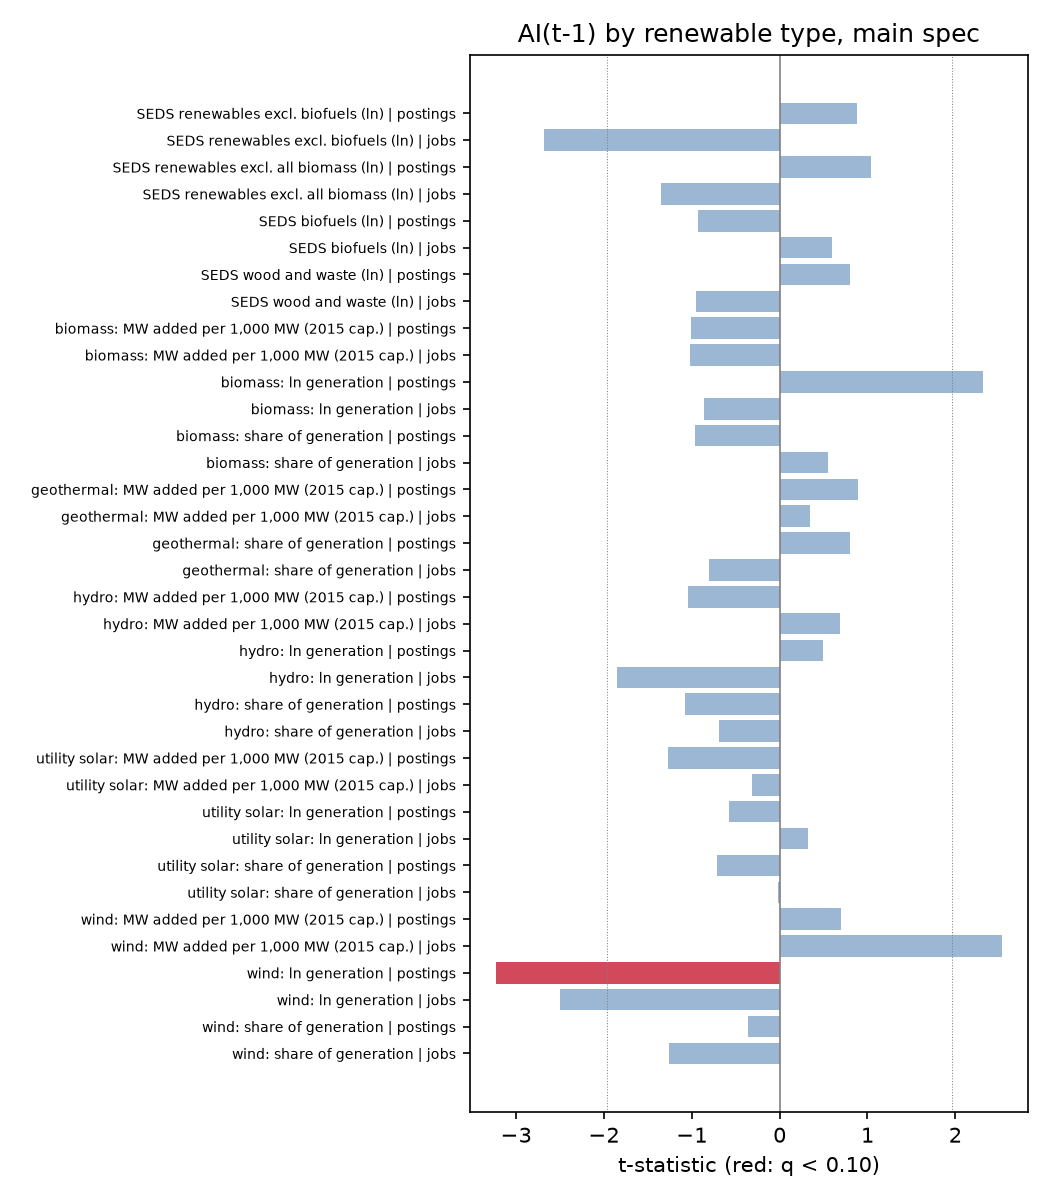

In [4]:
bt = pd.read_csv(T + 's2_bytype_table.csv'); display(bt.drop(columns=['tag', 'note']))
display(st[st.block == 'p2bytype'].round(4))
display(Markdown('**Biomass and what drives the negative SEDS total (pass 2, item 4):**')); display(pd.read_csv(T + 'p2_biomass_rows.csv').drop(columns='tag').round(4))
display(Image(F + 'fig_s2_bytype_t.png', width=560))

**Reading:** the one row that passed in pass 1, postings and ln wind generation (-0.048, q = 0.086), is **exploratory**. It loses significance with state trends (p = 0.14), the jobs version fails the lead test, and it runs against the expected sign.
Wood/waste and biofuels are null. The jobs association with the SEDS total comes from renewables without biofuels (-0.062), and its lead is just as large, so it reflects timing or selection, not transport fuel.

### Georgia
**Profile:** Georgia's data-center jobs per 1,000 rose from 2.01 (rank 22 of 50) in 2015 to 5.04 (rank 3) in 2024. Solar went from 0.1% to 7.7% of in-state generation (2015-2025); Georgia has no wind or geothermal generation. Large-load commitments: 15,600 MW across 32 customers by June 30, 2026 (Q2 2026 Large Load report, Docket 55378, headers Docket 56002, p. 1 [PDF p. 5]). The implied changes multiply each coefficient by Georgia's change in AI(t-1); they aren't forecasts.

,item,jobs_per1000,jobs_rank_of_50,postings_per1000,postings_rank_of_50
0,"AI level, 2015",2.011,22,NaN,NaN
1,"AI level, 2024",5.044,3,4.167,19.0
2,"AI level, 2025",5.035,2,6.220,25.0
3,AI change (jobs 2015-2024; postings 2018-2024),3.034,2,3.028,26.0


,outcome_label,ai_measure,window,implied,implied_lo,implied_hi,actual_change,at_most_share_of_actual
0,wind: share of generation,ai518210,2015-2025,-0.0259,-0.0671,0.0153,0.0000,inf
1,wind: share of generation,aipostp1000,2019-2025,-0.0024,-0.0154,0.0107,0.0000,inf
2,wind: ln generation,ai518210,2015-2025,-0.5550,-1.0028,-0.1072,NaN,NaN
3,wind: ln generation,aipostp1000,2019-2025,-0.1444,-0.2346,-0.0543,NaN,NaN
4,"wind: MW added per 1,000 MW (2015 cap.)",ai518210,2015-2025,5.8007,1.1998,10.4016,0.0000,inf
5,"wind: MW added per 1,000 MW (2015 cap.)",aipostp1000,2019-2025,1.8006,-3.3528,6.9540,0.0000,inf
6,utility solar: share of generation,ai518210,2015-2025,-0.0002,-0.0186,0.0183,0.0758,0.2459
7,utility solar: share of generation,aipostp1000,2019-2025,-0.0030,-0.0112,0.0053,0.0600,0.1872
8,utility solar: ln generation,ai518210,2015-2025,0.1292,-0.6689,0.9274,4.4592,0.2080
9,utility solar: ln generation,aipostp1000,2019-2025,-0.1394,-0.6229,0.3442,1.6443,0.3788


- wind: share of generation (jobs): Georgia has no wind generation in 2015-2025, so this doesn't apply.
- wind: share of generation (postings): Georgia has no wind generation in 2015-2025, so this doesn't apply.
- wind: ln generation (jobs): Georgia has no wind generation in 2015-2025, so this doesn't apply.
- wind: ln generation (postings): Georgia has no wind generation in 2015-2025, so this doesn't apply.
- wind: MW added per 1,000 MW (2015 cap.) (jobs): Georgia has no wind generation in 2015-2025, so this doesn't apply.
- wind: MW added per 1,000 MW (2015 cap.) (postings): Georgia has no wind generation in 2015-2025, so this doesn't apply.
- utility solar: share of generation (jobs): implied -0.000182 (95% CI -0.0186 to +0.0183) against an actual +0.0758 over 2015-2025: at most 25% of Georgia's actual change; the point estimate has the opposite sign.
- utility solar: share of generation (postings): implied -0.00295 (95% CI -0.0112 to +0.00533) against an actual +0.06 over 2019-2025

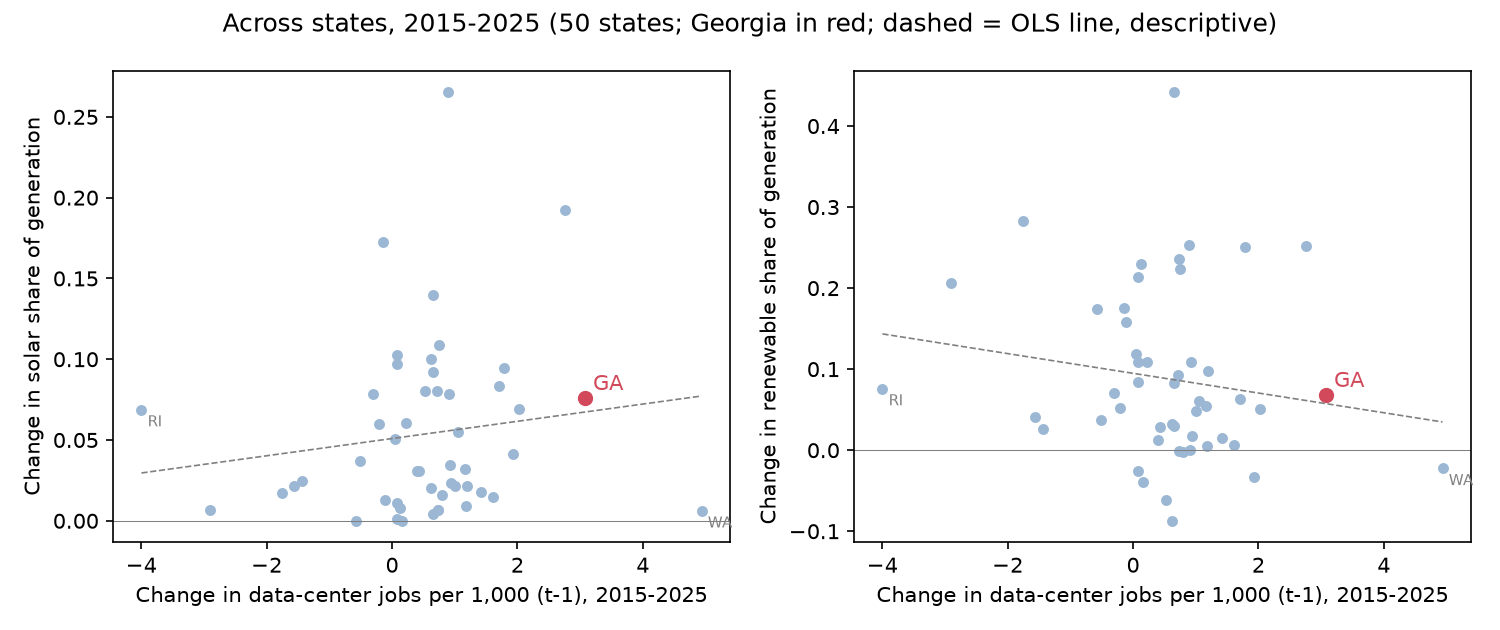

# Georgia Power's plans and large-load growth (prompt 09, section 2.4d)

Sources are only the Georgia PSC documents already in the project (`data/raw/georgia/`); nothing was downloaded. **Page convention: the printed page number, with the PDF page in brackets.** In the 2025 IRP main document, printed page = PDF page - 7 (front matter in roman numerals); the Q2 2026 report's printed numbering starts at its PDF p. 5. Every cite below was rechecked against that convention on 2026-11-07.

The latest IRP in the project is the **2025 IRP, Docket No. 56002** (`2025_IRP_Main_Document.pdf`, p. i [PDF p. 2]), approved by the Commission on July 15, 2025 (`2025_IRP_one_page_summary.pdf`, p. 1 [PDF p. 1]). The large-load reports are filed in **Docket No. 55378** (the 2023 IRP Update docket). The Q2 2026 report's cover letter cites both 55378 and 56002 (cover letter, unnumbered [PDF p. 1]), and its page headers carry Docket No. 56002 (pp. 1, 4 [PDF pp. 5, 8]). A later IRP filing, if one exists, isn't in the project.

## Load growth, and how the plan is tied to it
- Georgia Power projects about **8,200 MW of load growth** from winter 2024/2025 through winter 2030/2031, more than 2,200 MW above the 2023 IRP Update's projection. It projects nearly 6,000 MW as early as winter 2028/2029 and up to 9,400 MW through winter 2034/2035 (Docket 56002, 2025 IRP, p. 1 [PDF p. 8]).
- The forecast includes "specific information for the Company's growing pipeline of potential and committed large load customers" (p. 1 [PDF p. 8]). Large load means industrial load of at least 45 MW or commercial load of at least 115 MW (p. 35 [PDF p. 42]). Data centers are among the emerging industries whose growth "accelerated since 2021" (p. 31 [PDF p. 38]).
- The plan meets that growth with previously approved RFPs plus incremental requests of up to 1,500 MW "to meet load growth of approximately 8,200 MW through the winter of 2030/2031" (p. 4 [PDF p. 11]). The projected capacity-need tables assume the coal extensions below (p. 62 [PDF p. 69]).
- **Q2 2026 Large Load report** (filed Aug. 17, 2026, Docket 55378; headers Docket 56002): commitments reached **15,600 MW across 32 customers**, 8,700 MW of it by winter 2028/2029 (p. 1 [PDF p. 5]). Since the October 2023 IRP Update filing, commitments grew from 3,600 MW to 15,600 MW, and the economic-development pipeline from about 17,000 MW to about 84,800 MW through the mid-2030s. About 8,500 MW has broken ground (p. 4 [PDF p. 8], Table 2). In the report's attachment (tab Main), the Data Center/Crypto segment holds 19 projects and 9,149 MW with a Contract for Electric Service, plus 8 projects and 5,811 MW at Request for Service (`data/georgia_large_load_attachment.csv`).

## Coal
- The plan asks for **extended operation of Plant Scherer Unit 3 and Plant Gaston Units 1-4 and A beyond December 31, 2028** (p. 5 [PDF p. 12], request 7). The Company "is not pursuing retirement" of those units by the end of 2028 (p. 12 [PDF p. 19], note 8).
- For **Plant Bowen Units 1-4**, it recommends continued operation, with investment in the required environmental controls (p. 63 [PDF p. 70]). Gaston Units 1-4 burn mainly natural gas, with limited coal backup (p. 63 [PDF p. 70]).
- Earlier retirements: Plant Wansley Units 1-2 on August 31, 2022 (p. 12 [PDF p. 19]).
- 2024 energy for retail customers: 40% natural gas, 16% coal, 29% nuclear, 7% renewables, 2% hydro (p. 8 [PDF p. 15]).

## Gas
- More than 2,065 MW of battery storage and combustion-turbine resources by the end of 2027, plus active RFPs for **up to 9,500 MW of capacity** by the end of 2030. An all-source RFP issued in Q3 2025 targets 2032-2033 needs (p. 3 [PDF p. 10]).
- Upgrades at existing gas units: Plant McIntosh Units 10-11 (+194 MW by winter 2028/2029) and Units 1A-8A (+74 MW) (p. 59 [PDF p. 66]).

## Solar and other renewables
- Active RFPs for more than **3,500 MW of renewable resources by the end of 2030** (p. 3 [PDF p. 10]).
- RFPs for energy from **up to 4,000 MW of renewables by 2035**, including a 2026 Utility Scale RFP targeting 1,000 MW in commercial operation between November 30, 2030 and November 30, 2032 (p. 60 [PDF p. 67]).

## Storage
- An expedited certification application for **500 MW of Company-owned battery storage** (filed Aug. 16, 2024). The Commission certified the Moody, Robins, Hammond and McGrau Ford Phase II projects on Dec. 12, 2024, and the Winter 2027/2028 battery RFP went out on Aug. 9, 2024 (p. 11 [PDF p. 18]).
- The 65 MW, 4-hour Mossy Branch battery has operated since October 2024 (p. 70 [PDF p. 77]).
- **Reconciling the 500 MW and the ~780 MW (team item B5): they overlap; the 500 MW is part of the 780 MW.** The four certified projects in Attachment C.3 are Moody 49.5 + Robins 128 + Hammond 57.5 + McGrau Ford Phase 2 265 = 500 MW exactly (p. 128 [PDF p. 135]). The ~780 MW planned company-owned total adds the 2022 IRP McGrau Ford 2-hour battery (265 MW), the Fort Stewart 4-hour battery (13 MW) and a 2 MW demonstration (same page). Mossy Branch (65 MW) is already operating and is in neither figure.

## New and extended resources the IRP itself quantifies, by type
The IRP doesn't break the "up to 9,500 MW" of RFP capacity (p. 3 [PDF p. 10]) down by fuel. These are the resources its pages do quantify. It isn't a full breakdown, and the rows overlap in time.

| Type | MW | What it is | Docket 56002, 2025 IRP |
|---|---:|---|---|
| Gas/oil combustion turbines | 1,323 (summer; 1,070 winter) | Plant Yates Units 8-10, company-owned, in service 12/2026-08/2027 | p. 126 [PDF p. 133] (Attachment C.1) |
| Batteries | about 780 (nameplate), including the 500 MW certified in 2024 | Planned company-owned batteries in service 2026-2027 | p. 128 [PDF p. 135] (Attachment C.3) |
| Batteries and combustion turbines, combined | more than 2,065 | Additions by the end of 2027 | p. 3 [PDF p. 10] |
| Coal (extended, not new) | about 1,100 | Extended operation at Plants Scherer and Gaston | p. 2 [PDF p. 9] |
| Nuclear and gas upgrades | up to 400 | Upgrades at existing units | p. 2 [PDF p. 9] |
| Renewables (procurement targets) | more than 3,500 by 2030; up to 4,000 more by 2035 | Active RFPs; new RFPs | p. 3 [PDF p. 10]; p. 60 [PDF p. 67] |

## Reading
Georgia Power's 2025 IRP plans for about 8,200 MW of load growth through winter 2030/2031, driven largely by large-load customers. It meets that growth with a mix of new combustion turbines, batteries, coal-unit extensions, upgrades and renewable procurement. The pages don't say which fuel will serve the new large loads, and the 9,500 MW of RFP capacity isn't split by fuel. Data centers are the largest segment of committed large load in the Q2 2026 report's attachment. These are the utility's plans and statements, not estimates of ours. Our panel estimates (section 2.4b) can't attribute Georgia's solar growth to AI.

## Page check (team item 5, 2026-11-07)
In the Q2 2026 report, "15,600 MW" appears on p. 1 [PDF p. 5]: "reaching a total of 15,600 MW across 32 customers". It appears again on p. 4 [PDF p. 8]: "Customer commitments expanded from 3,600 MW to 15,600 MW", and in Table 2. Each citation in the project points to the page that states its claim. The Nov 4 summary's "PDF p. 8" (for "15,600 MW … up from 3,600 MW") and this note's p. 1 [PDF p. 5] (for "across 32 customers") are both correct. See `docs/2026-11-07/page-check-15600.md`.


In [5]:
display(pd.read_csv(T + 's2_georgia_ai_profile.csv').round(3))
gi = pd.read_csv(T + 's2_georgia_implied_vs_actual.csv')
display(gi[['outcome_label', 'ai_measure', 'window', 'implied', 'implied_lo', 'implied_hi', 'actual_change', 'at_most_share_of_actual']].round(4))
for s in gi.sentence: print('-', s)
display(Image(F + 'fig_s2_cross_state_georgia.png', width=900))
display(Markdown(open(T + 's2_georgia_irp_summary.md').read()))

**Reading:** Georgia's 7.6-point rise in its solar share can't be attributed to AI with these estimates (point estimates about zero or opposite in sign; the far end of the CI covers at most 25% with jobs and 19% with postings).
Georgia Power's 2025 IRP meets about 8,200 MW of load growth with combustion turbines, batteries (about 780 MW, which includes the 500 MW certified in 2024), coal extensions and renewable procurement. It doesn't split its 9,500 MW of RFP capacity by fuel.

## 3. What has AI been associated with?

**What we ran:** 15 outcomes x 2 AI measures (family "impact"), main spec; price outcomes drop the average price from the controls (X2). Pass 2 adds bounds per within-state SD of AI. The Queued Up outcome registered for this family (add-on A4) **wasn't run**: the file refuses scripted download.

$$Y_{st} = \beta\, AI_{s,t-1} + \gamma'\text{ctrl4}_{st} + \mu_s + \tau_t + \varepsilon_{st}$$

,outcome_label,ai,coef,ci95,pval,qval,N,years,status
0,ln commercial sales per person,"jobs per 1,000",-0.003724,"[-0.0286, +0.0211]",0.764410,0.929017,550,2015-2025,ok
1,ln commercial sales per person,"postings per 1,000",-0.00415,"[-0.0174, +0.00908]",0.531512,0.929017,350,2019-2025,ok
2,ln industrial sales per person,"jobs per 1,000",-0.004932,"[-0.0318, +0.0219]",0.713812,0.929017,550,2015-2025,ok
3,ln industrial sales per person,"postings per 1,000",-0.006484,"[-0.0191, +0.0061]",0.305402,0.803418,350,2019-2025,ok
4,ln residential sales per person,"jobs per 1,000",+0.0005763,"[-0.00461, +0.00576]",0.824301,0.929017,550,2015-2025,ok
5,ln residential sales per person,"postings per 1,000",-0.0001986,"[-0.00443, +0.00404]",0.925326,0.965831,350,2019-2025,ok
6,"commercial price, cents/kWh (ctrl3)","jobs per 1,000",+0.2204,"[-0.241, +0.682]",0.342080,0.803418,550,2015-2025,ok
7,"commercial price, cents/kWh (ctrl3)","postings per 1,000",+0.1956,"[-0.103, +0.494]",0.193996,0.803418,350,2019-2025,ok
8,"industrial price, cents/kWh (ctrl3)","jobs per 1,000",+0.07159,"[-0.439, +0.582]",0.779209,0.929017,550,2015-2025,ok
9,"industrial price, cents/kWh (ctrl3)","postings per 1,000",+0.1377,"[-0.0843, +0.36]",0.218564,0.803418,350,2019-2025,ok


,outcome_label,ai_measure,sd_within_ai,estimate,ci_lo,ci_hi,per_sd,per_sd_lo,per_sd_hi,pval,qval
0,ln commercial sales per person,ai518210,0.5703,-0.0037,-0.0286,0.0211,-0.0021,-0.0163,0.0120,0.7644,0.9290
1,ln commercial sales per person,aipostp1000,1.4459,-0.0041,-0.0174,0.0091,-0.0060,-0.0251,0.0131,0.5315,0.9290
2,ln industrial sales per person,ai518210,0.5703,-0.0049,-0.0318,0.0219,-0.0028,-0.0181,0.0125,0.7138,0.9290
3,ln industrial sales per person,aipostp1000,1.4459,-0.0065,-0.0191,0.0061,-0.0094,-0.0276,0.0088,0.3054,0.8034
4,ln residential sales per person,ai518210,0.5703,0.0006,-0.0046,0.0058,0.0003,-0.0026,0.0033,0.8243,0.9290
5,ln residential sales per person,aipostp1000,1.4459,-0.0002,-0.0044,0.0040,-0.0003,-0.0064,0.0058,0.9253,0.9658
6,"commercial price, cents/kWh (ctrl3)",ai518210,0.5703,0.2204,-0.2413,0.6820,0.1257,-0.1376,0.3889,0.3421,0.8034
7,"commercial price, cents/kWh (ctrl3)",aipostp1000,1.4459,0.1956,-0.1029,0.4941,0.2828,-0.1488,0.7145,0.1940,0.8034
8,"industrial price, cents/kWh (ctrl3)",ai518210,0.5703,0.0716,-0.4388,0.5820,0.0408,-0.2502,0.3319,0.7792,0.9290
9,"industrial price, cents/kWh (ctrl3)",aipostp1000,1.4459,0.1377,-0.0843,0.3597,0.1991,-0.1219,0.5201,0.2186,0.8034


,state,energy_only_share_pct_2015,rpm_share_pct_2025,restructured,restructured_check_rpm2025,near_cutoff_flag,near_cutoff_flag_check
0,PA,67.2,42.7,1,1,0,0
1,IL,67.1,37.6,1,1,0,0
2,OH,65.2,47.5,1,1,0,0
3,CT,57.7,25.4,1,1,0,0
4,MD,52.9,26.1,1,1,0,0
5,NY,52.7,18.0,1,1,0,0
6,ME,51.8,23.1,1,1,0,0
7,MA,51.7,57.8,1,1,0,0
8,NJ,47.4,24.4,1,1,0,0
9,NH,45.9,34.8,1,1,0,0


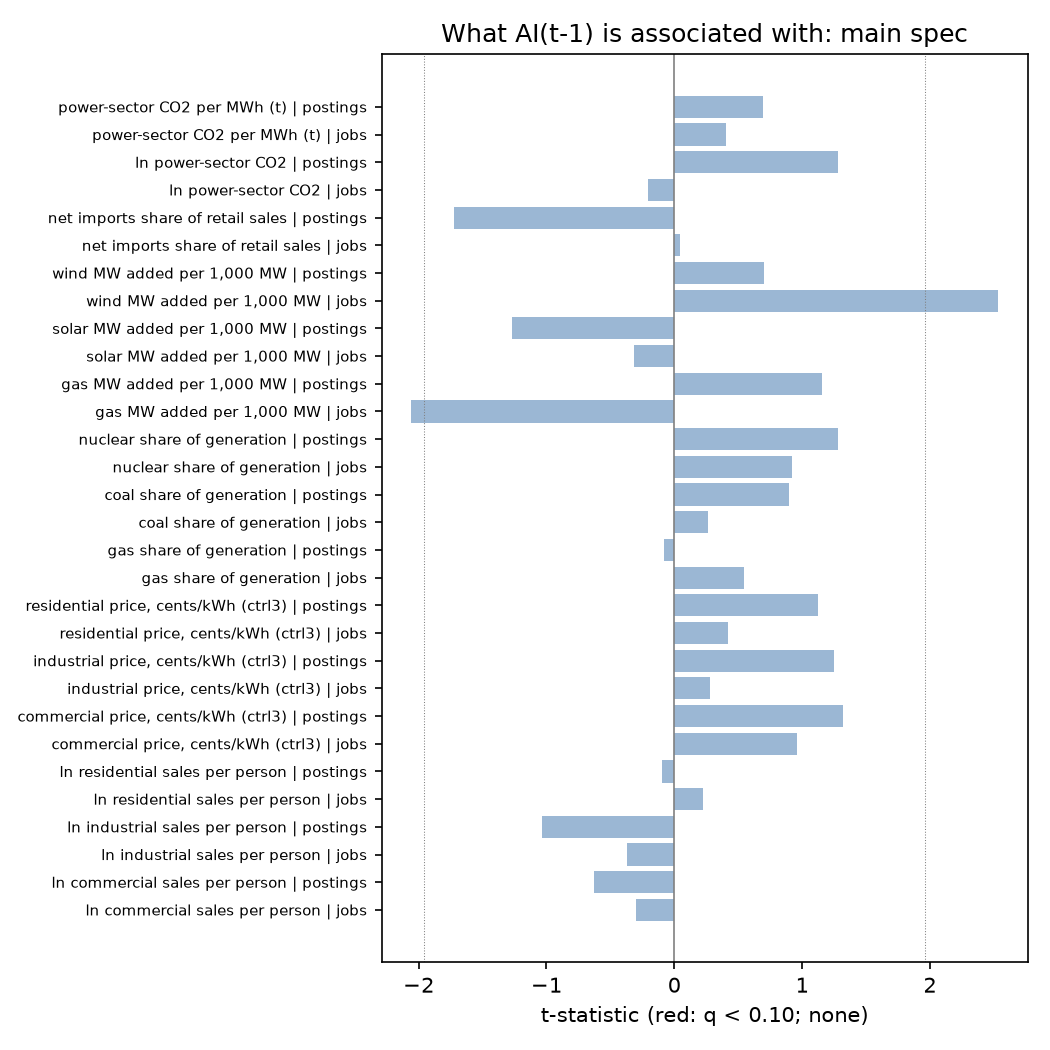

In [6]:
it = pd.read_csv(T + 's3_impact_table.csv'); display(it.drop(columns=['tag', 'note', 'lead_placebo', 'finding']))
display(pd.read_csv(T + 's3_bounds_per_within_sd.csv').drop(columns='tag').round(4))
display(pd.read_csv(T + 's3_restructured_classification.csv').round(1))
display(Image(F + 'fig_s3_impact_t.png', width=560))

**Reading:** nothing passes (smallest q = 0.44), so no lead placebo or restructuring model ran. Per within-state SD of data-center jobs (0.57 per 1,000 workers), commercial sales per person move between -1.6% and +1.2%, and the gas share between -0.5 and +0.9 points.
In 2015-2025 state data, AI growth isn't associated with detectable changes in sales, prices, the generation mix, imports or power-sector CO2.

## 4. Why did renewables grow nationally? (final)

**What we ran:** year effects from the main two-way model; the **full** drivers model (no year FE): state RPS/CES targets, solar resource x solar LCOE (LBNL), wind resource x wind LCOE (LBNL 2026 wind data), solar resource x ITC (CRS IF10479; P.L. 117-169), wind resource x PTC (CRS R43453; P.L. 116-260; P.L. 117-169), 2015 gas share x Henry Hub, the national main effects, AI(t-1) and ctrl4. Resource is EIA capacity factors in the first full year (X4), since NREL was unreachable. Tax-credit values carry printed page and [PDF page] cites in `s4_national_drivers.csv`. Interim rows are kept in `*_interim.csv`.

$$Y_{st} = \mu_s + b_1 RPS_{st} + b_2 (CF^{sol}_s LCOE^{sol}_t) + b_3 (CF^{wind}_s LCOE^{wind}_t) + b_4 (CF^{sol}_s ITC_t) + b_5 (CF^{wind}_s PTC_t) + b_6 (gas_{s,2015} HH_t) + c'D_t + a\, AI_{s,t-1} + \gamma'\text{ctrl4}_{st} + \varepsilon_{st}$$

,year,solar_lcoe_2025usd_mwh,wind_lcoe_2025usd_mwh,itc_pct,ptc_pct_of_full,hh_usd_mmbtu,us_dc_jobs_50
0,2015,121.36,57.01,30.0,100.0,2.62,296180.0
1,2016,93.97,50.78,30.0,100.0,2.52,300613.0
2,2017,94.75,47.71,30.0,80.0,2.99,312788.0
3,2018,75.95,42.02,30.0,60.0,3.15,332568.0
4,2019,63.76,43.31,30.0,40.0,2.56,342873.0
5,2020,54.95,44.13,26.0,60.0,2.03,360215.0
6,2021,51.58,44.14,26.0,60.0,3.89,387137.0
7,2022,50.53,39.83,30.0,100.0,6.45,465340.0
8,2023,55.40,47.91,30.0,100.0,2.53,484431.0
9,2024,58.41,49.38,30.0,100.0,2.19,482138.0


,outcome,ai_measure,drivers,statefe,twfe
0,ln_gen_solar,ai518210,+0.03032 (p=0.823),-0.04571 (p=0.794),+0.04204 (p=0.746)
1,ln_gen_solar,aipostp1000,-0.1026* (p=0.083),+0.1229*** (p=0.007),-0.04603 (p=0.565)
2,ln_gen_wind,ai518210,-0.1937*** (p=0.010),-0.2173*** (p=0.008),-0.1805** (p=0.016)
3,ln_gen_wind,aipostp1000,-0.04155*** (p=0.004),-0.001927 (p=0.869),-0.0477*** (p=0.002)
4,renew_share,ai518210,-0.0111* (p=0.073),-0.01242** (p=0.046),-0.01013 (p=0.100)
5,renew_share,aipostp1000,-0.004509** (p=0.037),+0.0005188 (p=0.774),-0.005681* (p=0.089)


,outcome,model,years,correlation,r_squared
0,renew_share,drivers,2015-2025,0.954,0.910
1,ln_gen_wind,drivers,2015-2025,0.947,0.897
2,ln_gen_solar,drivers,2015-2025,0.952,0.905


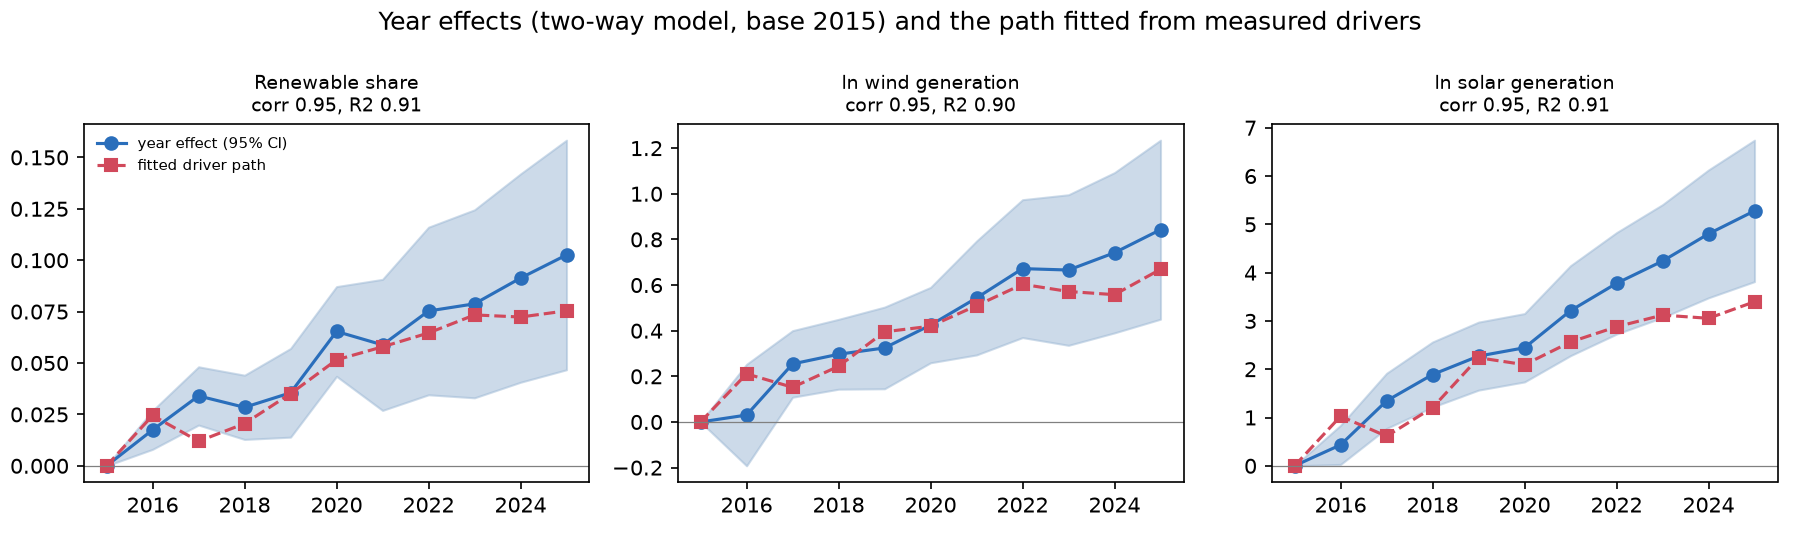

**AI isn't the national trend.** With data-center jobs, the renewable-share coefficient barely moves across the three models: -0.012 with state FE only (p = 0.046), -0.011 with measured drivers (p = 0.073) and -0.010 with two-way FE (p = 0.100). Leaving out year effects doesn't make it positive, so the national rise isn't loading on AI. **What the drivers show.** The year effects rise steadily for all three outcomes. A path fitted from measured drivers that vary by state, namely state RPS/CES targets (LBNL), solar resource x utility-scale solar LCOE (LBNL Utility-Scale Solar), solar resource x the solar ITC (CRS IF10479; P.L. 117-169), wind resource x wind cost (LBNL) and wind resource x the PTC (CRS R43453; P.L. 116-260; P.L. 117-169) and 2015 gas share x the Henry Hub price (EIA), correlates with them at 0.95 (renewable share), 0.95 (ln wind) and 0.95 (ln solar) over 11 years. That is consistent with these drivers' role but doesn't prove it: any series that rises over 2015-2025 correlates with a national trend. Solar LCOE fell from 121 to 51 $/MWh (2022) and rose to 61; the ITC was 30%, 26% for 2020-2021, and 30% again under the IRA. Postings and ln solar generation are positive with state FE only (+0.123, p = 0.007), but not once the measured drivers are in (-0.103, p = 0.083) or with year effects (-0.046, p = 0.565): the drivers absorb the shared 2019-2025 trend that the state-FE-only model loads on postings. All are associations.


In [7]:
display(pd.read_csv(T + 's4_national_drivers.csv')[['year', 'solar_lcoe_2025usd_mwh', 'wind_lcoe_2025usd_mwh', 'itc_pct', 'ptc_pct_of_full', 'hh_usd_mmbtu', 'us_dc_jobs_50']].round(2))
display(pd.read_csv(T + 's4_ai_three_models.csv'))
display(pd.read_csv(T + 's4_path_fit.csv')[['outcome', 'model', 'years', 'correlation', 'r_squared']].round(3))
display(Image(F + 'fig_s4_year_effects_drivers.png', width=950))
display(Markdown(open(T + 's4_writeup.md').read()))

**Reading:** the AI coefficient on the renewable share barely moves across state FE only, measured drivers and two-way FE (-0.012, -0.011, -0.010), so the national rise isn't loading on AI.
The full driver path correlates with the year effects at about 0.95. That's consistent with costs, tax credits and mandates driving the trend, but not proof: any rising series correlates with a national trend.

## 5. A better AI measure: "infrastructure + talent" index

**Relevance first.** Before any outcome result: does each AI measure predict commercial electricity sales per person, the most direct channel? The VA, TX and GA slopes rest on one cluster each, so they're not read as tests; instead, each is ranked among all 50 state-specific slopes.

**The index (2018-2023):** infrastructure = QCEW 518210 jobs, establishments and wages; talent = AI postings and OEWS computer and information research scientists (SOC 15-1111 = 15-1221). Software developers and data scientists are dropped, since no consistent 2018-2023 series exists without splicing. Innovation is dropped: AIPD is downloaded but unused, because inventor locations weren't available. OEWS suppression leaves 43 states. Index A = mean of dimension means of z-scores; Index B = PC1. Check: 2015-2023 without postings. Every result also without CA, CO and DE.

$$\ln S^{com}_{st} = \beta\, X_{s,t-1} + \gamma'\text{ctrl4}_{st} + \mu_s + \tau_t + \varepsilon_{st};\qquad \text{ranks: } \ln S^{com}_{st} = \textstyle\sum_j \beta_j (X_{s,t-1} \times 1[s=j]) + \ldots$$

,sample,ai_measure,version,slope,se,pval,ci_lo,ci_hi,per_within_sd,sd_within,N,n_states
0,all50,ai518210,pooled,-0.0037,0.0124,0.7644,-0.0286,0.0211,-0.0019,0.5212,550,50
5,all50,aipostp1000,pooled,-0.0041,0.0066,0.5315,-0.0174,0.0091,-0.0026,0.6181,350,50
10,all50,indexA,pooled,0.0120,0.0326,0.7151,-0.0538,0.0777,0.0021,0.1760,225,43
15,all50,indexB,pooled,-0.0023,0.0129,0.8578,-0.0283,0.0236,-0.0008,0.3665,225,43
20,all50,subInfra,pooled,-0.0139,0.0243,0.5684,-0.0629,0.0350,-0.0026,0.1899,225,43
25,all50,subTalent,pooled,0.0173,0.0242,0.4781,-0.0315,0.0661,0.0041,0.2389,225,43
30,all50,indexAcheck1523,pooled,0.0071,0.0215,0.7436,-0.0364,0.0505,0.0016,0.2302,327,44
35,noCACODE,ai518210,pooled,-0.0058,0.0126,0.6491,-0.0311,0.0196,-0.0029,0.5075,517,47
40,noCACODE,aipostp1000,pooled,-0.0006,0.0073,0.9355,-0.0153,0.0141,-0.0004,0.5958,329,47
45,noCACODE,indexA,pooled,0.0120,0.0328,0.7171,-0.0544,0.0784,0.0021,0.1771,213,40


,sample,ai_measure,state,slope,rank_of,rank_desc,share_states_larger,median_slope
0,all50,ai518210,VA,0.2420,50,3,0.0400,-0.0038
1,all50,ai518210,TX,0.0980,50,7,0.1200,-0.0038
2,all50,ai518210,GA,0.0202,50,21,0.4000,-0.0038
3,all50,aipostp1000,VA,0.0563,50,4,0.0600,-0.0109
4,all50,aipostp1000,TX,0.0129,50,10,0.1800,-0.0109
5,all50,aipostp1000,GA,0.0145,50,8,0.1400,-0.0109
6,all50,indexA,VA,0.3626,42,1,0.0000,-0.0260
7,all50,indexA,TX,0.0409,42,11,0.2381,-0.0260
8,all50,indexA,GA,0.0676,42,6,0.1190,-0.0260
9,noCACODE,ai518210,VA,0.2375,47,4,0.0638,-0.0050


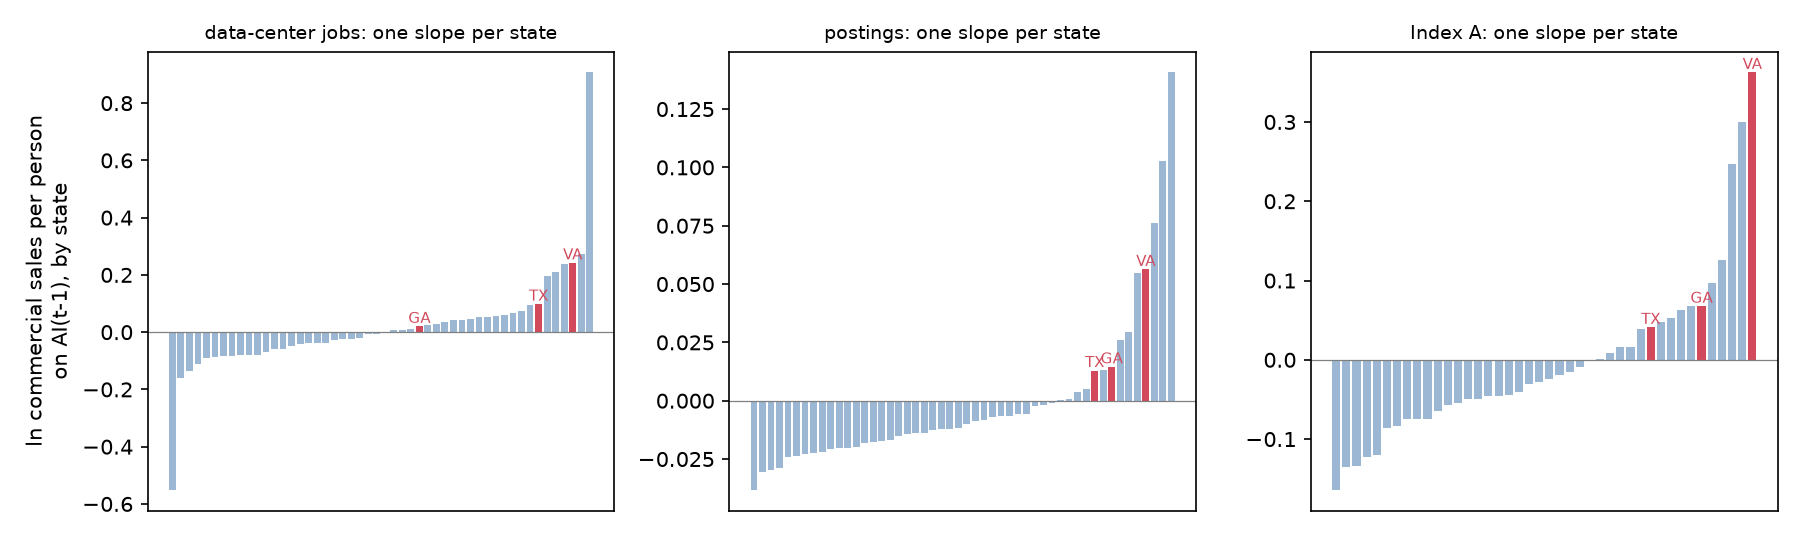

,year,c_jobs,c_estab,c_wage,c_post,c_rsci,all_five,infra_plus_rsci
0,2015,50,50,50,0,33,0,33
1,2016,50,50,50,0,34,0,34
2,2017,50,50,50,0,35,0,35
3,2018,50,50,50,50,39,39,39
4,2019,50,50,50,50,39,39,39
5,2020,50,50,50,50,39,39,39
6,2021,50,50,50,50,37,37,37
7,2022,50,50,50,50,34,34,34
8,2023,50,50,50,50,38,38,38
9,2024,50,50,50,50,34,34,34


,component,loading,variance_explained_pc1,version
0,c_jobs,0.526,0.538,main_2018_2023
1,c_estab,0.365,0.538,main_2018_2023
2,c_wage,0.571,0.538,main_2018_2023
3,c_post,0.506,0.538,main_2018_2023
4,c_rsci,0.084,0.538,main_2018_2023
5,c_jobs,0.632,0.547,check_2015_2023_no_postings
6,c_estab,0.414,0.547,check_2015_2023_no_postings
7,c_wage,0.654,0.547,check_2015_2023_no_postings
8,c_rsci,0.037,0.547,check_2015_2023_no_postings


,statistic,value
0,N state-years (main),226.000
1,states (main),43.000
2,"Cronbach alpha, 5 components",0.732
3,"Cronbach alpha, infrastructure",0.765
4,"Cronbach alpha, talent",0.337
5,PC1 variance explained,0.538
6,within-state SD (two-way demeaned) Index A,0.176
7,within-state SD Index B,0.364
8,within-state SD infrastructure,0.188
9,within-state SD talent,0.240


,Unnamed: 0,c_jobs,c_estab,c_wage,c_post,c_rsci
0,c_jobs,1.000,0.261,0.943,0.500,0.007
1,c_estab,0.261,1.000,0.357,0.546,-0.014
2,c_wage,0.943,0.357,1.000,0.656,0.070
3,c_post,0.500,0.546,0.656,1.000,0.203
4,c_rsci,0.007,-0.014,0.070,0.203,1.000


,check,N_states,pearson_index_a_2024,spearman_index_a_2024,spearman_index_b_2024
0,BTOS 2024 average share of firms using AI,30,0.551,0.525,0.540
1,Epoch current IT MW,22,0.062,-0.023,-0.010
2,Quid 2025 private AI investment,32,0.232,0.485,0.555


,years,soc_code,title,decision
0,2015-2018,15-1111,Computer and Information Research Scientists,kept
1,2019-2024,15-1221,Computer and Information Research Scientists,kept
2,2015-2018,15-1132 + 15-1133,"Software Developers, Applications + Systems Software (QA...",dropped: no consistent series
3,2019-2020,15-1256,Software Developers and Software QA Analysts and Testers,dropped
4,2021-2024,15-1252 (15-1253 separate),Software Developers,dropped
5,2015-2018,none,Data scientists have no category,dropped: no consistent series
6,2019-2020,15-2098,"Data Scientists and Mathematical Science Occupations, Al...",dropped
7,2021-2024,15-2051,Data Scientists,dropped


In [8]:
rel = pd.read_csv(T + 's5_relevance_first.csv'); display(rel[rel.version == 'pooled'].drop(columns='tag').round(4))
display(pd.read_csv(T + 's5_state_slope_ranks.csv').drop(columns='tag').round(4))
display(Image(F + 'fig_s5_state_slopes.png', width=950))
display(pd.read_csv(T + 's5_coverage.csv')); display(pd.read_csv(T + 's5_loadings.csv').round(3)); display(pd.read_csv(T + 's5_diagnostics.csv').round(3))
display(pd.read_csv(T + 's5_component_correlations.csv').round(3)); display(pd.read_csv(T + 's5_crossstate_checks.csv').round(3)); display(pd.read_csv(T + 's5_oews_mapping.csv'))

**Relevance reading:** pooled, neither the jobs measure, postings nor any index predicts commercial sales per person (e.g. Index A +0.012, p = 0.72). The per-state slopes are largest in Virginia (rank 3 of 50 with jobs; rank 1 of 42 with Index A), high for Texas (7th; 11th) and middling for Georgia (21st; 6th). So the measures track electricity use only where data-center load is concentrated.

,rows,min_q,q_below_10
sample,,,
all50,136,0.862657,0
noCACODE,136,0.900099,0


,index,outcome,estimate,pval,qval,per_sd,per_sd_lo,per_sd_hi,N,n_states
0,index_a,ln_ec,0.0120,0.3657,0.8726,0.0021,-0.0025,0.0068,225.0,43.0
1,index_a,ln_ee,-0.0094,0.5038,0.9620,-0.0017,-0.0066,0.0033,225.0,43.0
2,index_a,renew_share,-0.0177,0.2282,0.8627,-0.0031,-0.0082,0.0020,225.0,43.0
35,index_b,ln_ec,0.0031,0.6253,0.9620,0.0011,-0.0035,0.0058,225.0,43.0
36,index_b,ln_ee,-0.0017,0.7952,0.9620,-0.0006,-0.0056,0.0043,225.0,43.0
37,index_b,renew_share,-0.0121,0.1778,0.8627,-0.0044,-0.0110,0.0021,225.0,43.0
70,sub_infra,ln_ec,0.0052,0.6548,0.9620,0.0010,-0.0034,0.0054,225.0,43.0
71,sub_infra,ln_ee,-0.0035,0.7718,0.9620,-0.0007,-0.0052,0.0039,225.0,43.0
72,sub_infra,renew_share,-0.0250,0.1124,0.8627,-0.0048,-0.0107,0.0012,225.0,43.0
105,sub_talent,ln_ec,0.0072,0.4526,0.9471,0.0017,-0.0029,0.0063,225.0,43.0


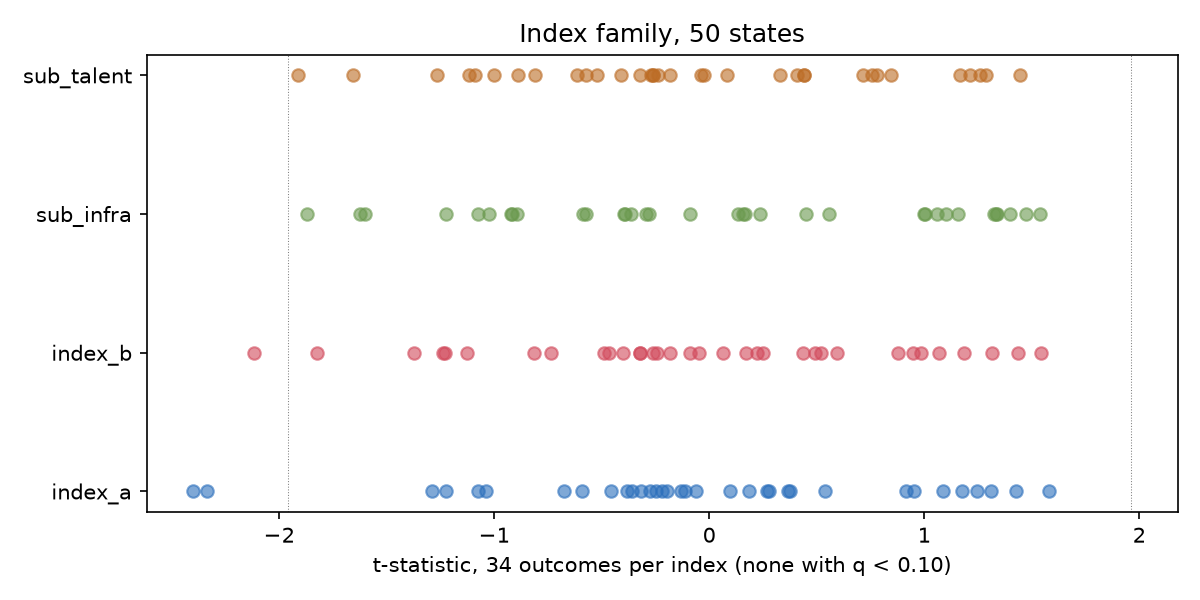

,sample,outcome,direction,estimate,se,pval,first_stage_F,informative,N
0,all50,ln_ec,postings instrumented by jobs,0.037,0.098,0.710,0.512,False,350
1,all50,ln_ec,jobs instrumented by postings,-0.066,0.187,0.725,0.472,False,350
2,all50,ln_ee,postings instrumented by jobs,-0.003,0.102,0.979,0.512,False,350
3,all50,ln_ee,jobs instrumented by postings,0.080,0.216,0.714,0.472,False,350
4,all50,renew_share,postings instrumented by jobs,-0.074,0.106,0.489,0.512,False,350
5,all50,renew_share,jobs instrumented by postings,-0.216,0.353,0.543,0.472,False,350
6,noCACODE,ln_ec,postings instrumented by jobs,0.012,0.055,0.828,1.530,False,329
7,noCACODE,ln_ec,jobs instrumented by postings,0.012,0.062,0.853,1.539,False,329
8,noCACODE,ln_ee,postings instrumented by jobs,0.021,0.069,0.757,1.530,False,329
9,noCACODE,ln_ee,jobs instrumented by postings,-0.034,0.067,0.615,1.539,False,329


In [9]:
ix = pd.read_csv(T + 's5_index_family.csv')
display(ix[(ix.status == 'ok') & (ix.family == 'index')].groupby('sample').agg(rows=('qval', 'size'), min_q=('qval', 'min'), q_below_10=('qval', lambda s: (s < .1).sum())))
display(ix[(ix.status == 'ok') & (ix['sample'] == 'all50') & (ix.outcome.isin(['ln_ec', 'ln_ee', 'renew_share']))][['index', 'outcome', 'estimate', 'pval', 'qval', 'per_sd', 'per_sd_lo', 'per_sd_hi', 'N', 'n_states']].round(4))
display(Image(F + 'fig_s5_index_family.png', width=700))
display(pd.read_csv(T + 's5_2sls.csv').drop(columns='tag').round(3))

**Index reading:** no index row has q < 0.10, on all 50 states or without CA, CO and DE (smallest q 0.86 and 0.90). The 2SLS checks are uninformative (first-stage F 0.5 and 1.5): postings and data-center jobs barely move together within states.
A broader measure doesn't uncover an association that the single measures miss.

### Add-on: groupings, land as a moderator, queue outcome
**Groupings** (cut points fixed before results): 2025 Quid investment (one year only, so grouping only) >= $1B / $100M-$1B / < $100M; tertiles of investment per TWh of 2015 sales; tertiles of 2015 data-center jobs per TWh. Model: AI(t-1) x group; joint Wald test of group differences, BH within each grouping. **Land:** AI(t-1) x land area per TWh of 2015 sales (NREL unreachable); the registered version is in levels, and X5 adds logs and a version without Alaska (post hoc). **Queue outcome (A4):** not run, because Queued Up refuses scripted download.

In [10]:
g = pd.read_csv(T + 'addon_groupings.csv')
display(g[g.status == 'ok'].groupby(['sample', 'grouping']).agg(tests=('joint_q', 'size'), min_q=('joint_q', 'min'), q_below_10=('joint_q', lambda s: (s < .1).sum())))
display(g[g.joint_q < .1].drop(columns='tag').round(4))
lm = pd.read_csv(T + 'addon_land_moderator.csv'); lx = pd.read_csv(T + 'addon_land_moderator_X5.csv')
display(lm[lm.interaction_q < .1].drop(columns='tag'))
display(lx.groupby(['sample', 'version']).agg(tests=('interaction_q', 'size'), q_below_10=('interaction_q', lambda s: (s < .1).sum())))
display(lx[lx.interaction_q < .1].drop(columns='tag'))

tests     min_q  q_below_10
sample   grouping                                       
all50    grp_invest             44  0.179799           0
         grp_invest_per_twh     44  0.407726           0
         grp_jobs_per_twh       44  0.157789           0
noCACODE grp_invest             44  0.101451           0
         grp_invest_per_twh     44  0.347491           0
         grp_jobs_per_twh       44  0.014967           2

,sample,grouping,ai_measure,outcome,joint_F,joint_p,slope_g1,slope_g2,slope_g3,groups,n_states,N,status,joint_q
233,noCACODE,grp_jobs_per_twh,ai518210,ln_gen_geo,58.4919,0.0003,1.1180,0.6911,0.5798,low/mid/high,2/3/1,65,ok,0.0150
260,noCACODE,grp_jobs_per_twh,aipostp1000,ln_seds_woodwaste,6.2322,0.0040,-0.0206,0.0251,0.0323,low/mid/high,17/16/14,282,ok,0.0886


,sample,ai_measure,outcome,ai_at_mean_room,ai_p,interaction,interaction_se,interaction_p,room_sd,N,status,interaction_q
11,all50,ai518210,add_hydro_per1000,-0.304401,0.120783,-1.543889e-04,5.410042e-05,6.314311e-03,13043.891802,550,ok,0.030870
16,all50,ai518210,ln_gen_bio,0.058260,0.129328,3.227349e-05,1.064979e-05,3.926881e-03,13174.349390,526,ok,0.021598
24,all50,aipostp1000,renew_share,-0.004833,0.141875,-8.811116e-08,2.061402e-08,8.818004e-05,13043.891802,350,ok,0.000970
28,all50,aipostp1000,share_solar,-0.000488,0.702700,-5.058624e-08,9.833841e-09,4.710756e-06,13043.891802,350,ok,0.000104
29,all50,aipostp1000,ln_gen_solar,-0.068358,0.350509,5.521967e-06,1.728200e-06,2.470621e-03,13178.873817,333,ok,0.015530
32,all50,aipostp1000,ln_gen_hydro,0.003848,0.843907,4.479190e-07,1.772071e-07,1.490362e-02,13305.668776,336,ok,0.059614
37,all50,aipostp1000,share_bio,-0.000538,0.271605,9.991644e-09,3.903695e-09,1.361795e-02,13043.891802,350,ok,0.059614
38,all50,aipostp1000,ln_gen_bio,0.030172,0.050433,4.497761e-07,1.086467e-07,1.396572e-04,13174.349390,337,ok,0.001229
40,all50,aipostp1000,ln_seds_woodwaste,0.010426,0.407780,-9.192031e-07,2.585530e-07,8.482573e-04,13043.891802,300,ok,0.006221
42,all50,aipostp1000,ln_seds_re_exbiomass,0.020511,0.288608,-9.300810e-07,2.068020e-07,4.228288e-05,13043.891802,300,ok,0.000620


tests  q_below_10
sample   version                      
all50    level_noAK     44           5
         log_room       44           2
noCACODE level_noAK     44           6
         log_room       44           3

,sample,version,ai_measure,outcome,interaction,interaction_p,N,interaction_q
8,all50,log_room,ai518210,add_solar_per1000,2.954421,0.001171,550,0.025752
40,all50,log_room,aipostp1000,ln_seds_woodwaste,-0.019929,0.000164,300,0.007219
50,all50,level_noAK,ai518210,share_solar,0.000007,0.001588,539,0.023289
52,all50,level_noAK,ai518210,add_solar_per1000,0.003518,0.001394,539,0.023289
69,all50,level_noAK,aipostp1000,share_wind,0.000004,0.002516,343,0.027681
70,all50,level_noAK,aipostp1000,ln_gen_wind,0.000017,0.000879,286,0.023289
82,all50,level_noAK,aipostp1000,ln_gen_bio,0.000010,0.005746,330,0.050561
92,noCACODE,log_room,ai518210,ln_gen_wind,0.106344,0.000661,422,0.014540
96,noCACODE,log_room,ai518210,add_solar_per1000,3.056092,0.002144,517,0.031451
128,noCACODE,log_room,aipostp1000,ln_seds_woodwaste,-0.019179,0.000620,282,0.014540


**Add-on reading:** no grouping difference survives BH on all 50 states (smallest q 0.16-0.41). Without CA, CO and DE, two rows pass in the jobs-per-TWh grouping (ln geothermal generation, wood/waste), out of 44 tests; neither is on a main outcome. The registered land moderator gives 11 of 44 rows with q < 0.10, but Alaska (land per TWh nine times the next state) drives them: in logs or without AK, a different and mostly positive set of rows passes. So it's read as fragile and exploratory, not as a land effect.